# Exploring petgraph: a tiny computation DAG

This notebook builds a small **directed acyclic graph (DAG)** with
[petgraph](https://docs.rs/petgraph), then:

1. checks that it really is acyclic,
2. sorts the nodes into **layers**,
3. runs a computation through it: every node is either a constant input, a sum (`+`) or a difference (`−`),
4. draws the graph and the results.

It runs on the [evcxr](https://github.com/evcxr/evcxr) Rust kernel for Jupyter. Every cell is plain Rust.
One evcxr rule to know: variables that are kept between cells need an explicit type, such as `let g: CalcGraph = …`.

## Setup

`:dep` is an evcxr command that adds a crate, like a line in `Cargo.toml`.

In [2]:
:dep petgraph = "0.8.3"

In [3]:
use std::collections::HashMap;
use std::io::Write;
use std::process::{Command, Stdio};

use petgraph::algo::{is_cyclic_directed, tarjan_scc, toposort};
use petgraph::dot::{Config, Dot, RankDir};
use petgraph::graph::{DiGraph, EdgeIndex, EdgeReference, NodeIndex};
use petgraph::visit::EdgeRef;
use petgraph::Direction;

A small helper to show pictures: `render` passes DOT text to Graphviz's `dot`
and returns the SVG. evcxr shows a cell's last value with its `evcxr_display`
method, so returning an `Svg` makes the picture appear under the cell.

In [4]:
pub struct Svg(String);

impl Svg {
    pub fn evcxr_display(&self) {
        println!("EVCXR_BEGIN_CONTENT image/svg+xml\n{}\nEVCXR_END_CONTENT", self.0);
    }
}

fn render(dot: &str) -> Svg {
    let mut child = Command::new("dot")
        .arg("-Tsvg")
        .stdin(Stdio::piped())
        .stdout(Stdio::piped())
        .spawn()
        .expect("Graphviz `dot` must be installed");
    child.stdin.take().unwrap().write_all(dot.as_bytes()).unwrap();
    let svg = String::from_utf8(child.wait_with_output().unwrap().stdout).unwrap();
    // Drop the XML prolog so the SVG can sit inside HTML.
    Svg(svg[svg.find("<svg").unwrap_or(0)..].to_string())
}

## The model

The node weight says what a node computes. The edge weight is the **operand
position**, which only matters for `Sub`, because `a − b ≠ b − a`.

`DiGraph<N, E>` is petgraph's main directed graph type. Nodes and edges are
addressed by `NodeIndex` and `EdgeIndex`.

In [5]:
#[derive(Debug, Clone, Copy)]
enum Op {
    /// Source node holding a constant.
    Input(i64),
    /// Sum of all inputs.
    Add,
    /// First input minus all remaining inputs.
    Sub,
}

#[derive(Debug, Clone)]
struct Node {
    name: &'static str,
    op: Op,
}

/// Edge weight = operand position.
type Operand = usize;
type CalcGraph = DiGraph<Node, Operand>;

fn op_symbol(op: Op) -> String {
    match op {
        Op::Input(x) => format!("input {x}"),
        Op::Add => "+".into(),
        Op::Sub => "−".into(),
    }
}

## Building the graph

`add_node` returns the new node's index. `add_edge(from, to, weight)` connects two nodes.

In [6]:
fn build_graph() -> CalcGraph {
    let mut g = CalcGraph::new();
    let mut node = |name, op| g.add_node(Node { name, op });

    let a = node("a", Op::Input(10));
    let b = node("b", Op::Input(4));
    let c = node("c", Op::Input(3));
    let d = node("d", Op::Input(7));
    let s1 = node("s1", Op::Add);
    let s2 = node("s2", Op::Sub);
    let s3 = node("s3", Op::Sub);
    let s4 = node("s4", Op::Add);
    let out = node("out", Op::Sub);

    let edges = [
        (a, s1, 0), (b, s1, 1),              // s1  = a + b
        (b, s2, 0), (c, s2, 1),              // s2  = b - c
        (s1, s3, 0), (s2, s3, 1),            // s3  = s1 - s2
        (s2, s4, 0), (d, s4, 1), (a, s4, 2), // s4  = s2 + d + a
        (s3, out, 0), (s4, out, 1),          // out = s3 - s4
    ];
    for (from, to, pos) in edges {
        g.add_edge(from, to, pos);
    }
    g
}

let g: CalcGraph = build_graph();
println!("{} nodes, {} edges", g.node_count(), g.edge_count());

9 nodes, 11 edges


## Drawing it

`petgraph::dot::Dot` writes a graph in Graphviz's DOT format.
`with_attr_getters` lets us choose each node's and edge's attributes (label,
colour, …). `to_dot` can optionally add layers, values and highlighted edges,
which we fill in as the notebook goes on.

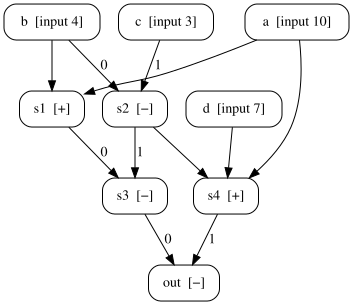

In [7]:
const COLORS: [&str; 6] = ["#cfe8ff", "#d6f5d6", "#fff2b3", "#ffd9b3", "#f2c6de", "#e0d4f7"];

fn to_dot(
    g: &CalcGraph,
    layer: Option<&HashMap<NodeIndex, usize>>,
    value: Option<&HashMap<NodeIndex, i64>>,
    highlight: &[EdgeIndex],
) -> String {
    let node_attrs = |_: &CalcGraph, (n, node): (NodeIndex, &Node)| {
        let mut label = format!("{}  [{}]", node.name, op_symbol(node.op));
        let mut fill = "white";
        if let Some(layer) = layer {
            label += &format!("\\nlayer {}", layer[&n]);
            fill = COLORS[layer[&n] % COLORS.len()];
        }
        if let Some(value) = value {
            label += &format!("\\n= {}", value[&n]);
        }
        format!("label=\"{label}\" shape=box style=\"rounded,filled\" fillcolor=\"{fill}\"")
    };
    let edge_attrs = |g: &CalcGraph, e: EdgeReference<Operand>| {
        // Show the operand position only where order matters.
        let mut attrs = match g[e.target()].op {
            Op::Sub => format!("label=\"{}\"", e.weight()),
            _ => String::new(),
        };
        if highlight.contains(&e.id()) {
            attrs += " color=red fontcolor=red penwidth=2";
        }
        attrs
    };

    let dot = Dot::with_attr_getters(
        g,
        &[Config::NodeNoLabel, Config::EdgeNoLabel, Config::RankDir(RankDir::TB)],
        &edge_attrs,
        &node_attrs,
    );
    let mut out = format!("{dot:?}");

    // Dot can't emit subgraphs, so add one `rank=same` group per layer
    // to make Graphviz draw each layer in one row.
    if let Some(layer) = layer {
        let closing = out.rfind('}').unwrap();
        let depth = layer.values().max().copied().unwrap_or(0);
        let mut ranks = String::new();
        for l in 0..=depth {
            let ids: Vec<_> = g
                .node_indices()
                .filter(|n| layer[n] == l)
                .map(|n| n.index().to_string())
                .collect();
            ranks += &format!("    {{ rank=same; {} }}\n", ids.join("; "));
        }
        out.insert_str(closing, &ranks);
    }
    out
}

render(&to_dot(&g, None, None, &[]))

## Is it really a DAG?

petgraph offers two checks:

* `is_cyclic_directed(&g)` gives a plain yes/no answer.
* `toposort(&g, None)` returns a **topological order** (every node comes after all of its inputs), or a `Cycle` error naming a node on a cycle.

We need the order anyway, both for layering and for computing.

In [8]:
println!("is_cyclic_directed: {}", is_cyclic_directed(&g));

let topo: Vec<NodeIndex> = toposort(&g, None).expect("graph has a cycle");
let names: Vec<&str> = topo.iter().map(|&n| g[n].name).collect();
println!("topological order: {names:?}");

is_cyclic_directed: false
topological order: ["d", "c", "b", "s2", "a", "s4", "s1", "s3", "out"]


### Counter-example: adding a cycle

One extra edge `out → a` creates a cycle. Both checks catch it.
`tarjan_scc` splits a graph into **strongly connected components**: groups of
nodes that can all reach each other. Any group with more than one node is part
of a cycle, so we draw the edges inside it in red.

is_cyclic_directed: true
toposort error: cycle through "out"
nodes on a cycle: ["a", "out", "s1", "s3", "s4"]


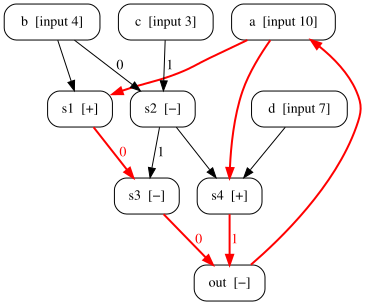

In [9]:
fn find(g: &CalcGraph, name: &str) -> NodeIndex {
    g.node_indices().find(|&n| g[n].name == name).unwrap()
}

let mut cyclic: CalcGraph = g.clone();
let out: NodeIndex = find(&g, "out");
let a: NodeIndex = find(&g, "a");
cyclic.add_edge(out, a, 0);

println!("is_cyclic_directed: {}", is_cyclic_directed(&cyclic));
match toposort(&cyclic, None) {
    Ok(_) => println!("unexpected: still acyclic"),
    Err(c) => println!("toposort error: cycle through {:?}", cyclic[c.node_id()].name),
}

let scc: Vec<NodeIndex> = tarjan_scc(&cyclic).into_iter().find(|c| c.len() > 1).unwrap();
let mut scc_names: Vec<&str> = scc.iter().map(|&n| cyclic[n].name).collect();
scc_names.sort();
println!("nodes on a cycle: {scc_names:?}");

let cycle_edges: Vec<EdgeIndex> = cyclic
    .edge_references()
    .filter(|e| scc.contains(&e.source()) && scc.contains(&e.target()))
    .map(|e| e.id())
    .collect();
render(&to_dot(&cyclic, None, None, &cycle_edges))

## Layers

**Longest-path layering**: inputs go in layer 0, and every other node sits one
layer below its deepest input. Walking in topological order guarantees each
input already has a layer when we need it. Nodes in the same layer don't
depend on each other, so they could be computed in parallel.

In [10]:
fn layers(g: &CalcGraph, topo: &[NodeIndex]) -> HashMap<NodeIndex, usize> {
    let mut layer = HashMap::new();
    for &n in topo {
        let l = g
            .neighbors_directed(n, Direction::Incoming)
            .map(|p| layer[&p] + 1)
            .max()
            .unwrap_or(0);
        layer.insert(n, l);
    }
    layer
}

let layer: HashMap<NodeIndex, usize> = layers(&g, &topo);
let depth: usize = layer.values().max().copied().unwrap_or(0);
for l in 0..=depth {
    let mut names: Vec<_> = g.node_indices().filter(|n| layer[n] == l).map(|n| g[n].name).collect();
    names.sort();
    println!("layer {l}: {}", names.join(", "));
};

layer 0: a, b, c, d
layer 1: s1, s2
layer 2: s3, s4
layer 3: out


## Computing

The same idea again: in topological order, all of a node's inputs are already
computed. `edges_directed(n, Incoming)` gives the incoming edges. We sort them
by operand position so that `Sub` subtracts in the right order.

In [11]:
fn evaluate(g: &CalcGraph, topo: &[NodeIndex]) -> HashMap<NodeIndex, i64> {
    let mut value = HashMap::new();
    for &n in topo {
        let mut inputs: Vec<(Operand, i64)> = g
            .edges_directed(n, Direction::Incoming)
            .map(|e| (*e.weight(), value[&e.source()]))
            .collect();
        inputs.sort_by_key(|&(pos, _)| pos);
        let mut vals = inputs.into_iter().map(|(_, v)| v);

        let v = match g[n].op {
            Op::Input(x) => x,
            Op::Add => vals.sum(),
            Op::Sub => {
                let first = vals.next().unwrap_or(0);
                first - vals.sum::<i64>()
            }
        };
        value.insert(n, v);
    }
    value
}

/// Prints each node as an expression, e.g. `s3 = s1 - s2 = 13`.
fn print_results(g: &CalcGraph, topo: &[NodeIndex], value: &HashMap<NodeIndex, i64>) {
    for &n in topo {
        let mut es: Vec<_> = g.edges_directed(n, Direction::Incoming).collect();
        es.sort_by_key(|e| *e.weight());
        let inputs: Vec<_> = es.iter().map(|e| g[e.source()].name).collect();
        let expr = match g[n].op {
            Op::Input(_) => "const".to_string(),
            Op::Add => inputs.join(" + "),
            Op::Sub => inputs.join(" - "),
        };
        println!("{:>4} = {:<14} = {}", g[n].name, expr, value[&n]);
    }
}

let value: HashMap<NodeIndex, i64> = evaluate(&g, &topo);
print_results(&g, &topo, &value);

   d = const          = 7
   c = const          = 3
   b = const          = 4
  s2 = b - c          = 1
   a = const          = 10
  s4 = s2 + d + a     = 18
  s1 = a + b          = 14
  s3 = s1 - s2        = 13
 out = s3 - s4        = -5


## The full picture

Each row is a layer, and each node shows its operation, layer and computed value.

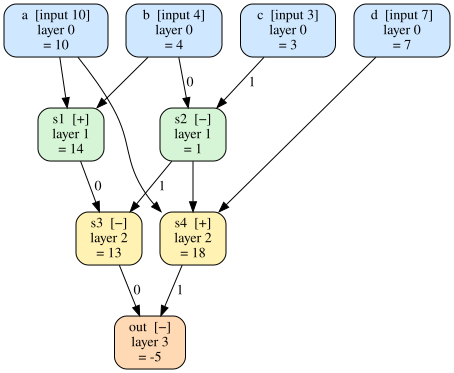

In [12]:
render(&to_dot(&g, Some(&layer), Some(&value), &[]))

## Play with it

Node weights can be changed in place with `g[index]`. The structure stays the
same, so the topological order and the layers stay valid, and we only need to
re-run `evaluate`. Here input `c` changes from 3 to 8.

Changing `a` would have no effect on `out`. Work it out by hand:
`out = (a + b − s2) − (s2 + d + a)`, and the `a` cancels. Try it!

   d = const          = 7
   c = const          = 8
   b = const          = 4
  s2 = b - c          = -4
   a = const          = 10
  s4 = s2 + d + a     = 13
  s1 = a + b          = 14
  s3 = s1 - s2        = 18
 out = s3 - s4        = 5


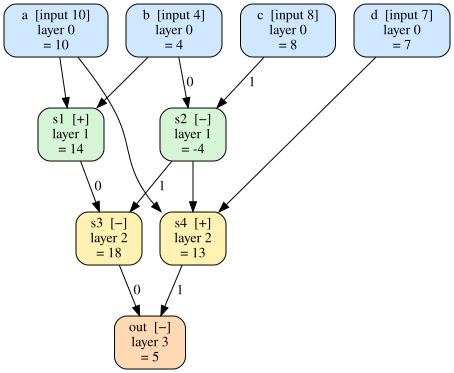

In [13]:
let mut g2: CalcGraph = g.clone();
let c: NodeIndex = find(&g2, "c");
g2[c].op = Op::Input(8);
let value2: HashMap<NodeIndex, i64> = evaluate(&g2, &topo);
print_results(&g2, &topo, &value2);
render(&to_dot(&g2, Some(&layer), Some(&value2), &[]))

## Where to go next

* `petgraph::acyclic::Acyclic`: a graph wrapper that refuses any edge that would create a cycle.
* `DfsSpace`: lets repeated `toposort` calls reuse memory.
* `StableGraph`: keeps indices valid after you remove nodes.
* `algo::dijkstra`, `algo::astar`, `algo::bellman_ford`: shortest paths over weighted edges.